<a href="https://colab.research.google.com/github/infinityxrudra/CFD-and-Heat-Transfer-Simulations/blob/main/01_NACAAirfoil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 1: External Flow over a NACA 0012 Airfoil

**Aim:** Study the influence of angle of attack on the velocity, pressure, wake, and qualitative force trends around a NACA 0012 airfoil.

**Numerical method:** Cartesian immersed-geometry projection solver with pressure correction and penalization inside the airfoil mask.

> **Scope:** The force coefficients are qualitative. Use the case to study discretization, convergence, pressure distribution, and wake trends rather than to claim high-fidelity aerodynamic data.

This Google Colab notebook is self-contained. It reconstructs the tested solver inside the temporary Colab runtime, runs it, displays quantitative plots and an inline field contour, and packages every output file for download.

> **Colab workflow:** Choose a run mode, use **Runtime > Run all**, then download the results ZIP from the final cell. `quick` is only a workflow check; use `lab` or an approved `custom` case for submission.

In [ ]:
#@title 1. Prepare the self-contained Colab runtime

from pathlib import Path
import shutil
import subprocess
import sys
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

IN_COLAB = False
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    colab_files = None


def run_solver(script_path, arguments, output_dir, timeout=1800):
    output_dir = Path(output_dir)
    if output_dir.exists():
        shutil.rmtree(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    command = [sys.executable, str(script_path), *[str(value) for value in arguments]]
    print("Running:", " ".join(command))
    completed = subprocess.run(command, cwd=output_dir, capture_output=True, text=True, timeout=timeout)
    (output_dir / "solver_stdout.log").write_text(completed.stdout, encoding="utf-8")
    (output_dir / "solver_stderr.log").write_text(completed.stderr, encoding="utf-8")
    if completed.stdout.strip():
        print(completed.stdout.strip())
    if completed.returncode != 0:
        raise RuntimeError(completed.stderr.strip() or f"Solver exited with code {completed.returncode}")
    if completed.stderr.strip():
        print(completed.stderr.strip())
    return output_dir


def read_csv(path):
    data = np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8")
    return np.atleast_1d(data)


def show_summary(path):
    text = Path(path).read_text(encoding="utf-8").strip()
    display(Markdown(f"### Solver summary\n```text\n{text}\n```"))
    return text


def list_outputs(output_dir):
    rows = []
    for path in sorted(Path(output_dir).iterdir()):
        if path.is_file():
            size = path.stat().st_size
            if size < 1024:
                size_text = f"{size} B"
            elif size < 1024**2:
                size_text = f"{size / 1024:.1f} KB"
            else:
                size_text = f"{size / 1024**2:.1f} MB"
            rows.append((path.name, size_text))
    table = "\n".join(f"| `{name}` | {size} |" for name, size in rows)
    display(Markdown(f"### Generated files\n| File | Size |\n|---|---:|\n{table}"))
    return rows


def read_structured_vtk(path):
    lines = Path(path).read_text(encoding="utf-8").splitlines()
    dims_index = next(i for i, line in enumerate(lines) if line.startswith("DIMENSIONS "))
    _, nx, ny, nz = lines[dims_index].split()
    nx, ny, nz = int(nx), int(ny), int(nz)
    if nz != 1:
        raise ValueError("Only 2D structured VTK files are supported by this notebook preview")
    points_index = next(i for i, line in enumerate(lines) if line.startswith("POINTS "))
    npoints = int(lines[points_index].split()[1])
    points = np.array([[float(v) for v in lines[points_index + 1 + k].split()[:3]] for k in range(npoints)])
    x = points[:, 0].reshape(ny, nx)
    y = points[:, 1].reshape(ny, nx)
    data_index = next(i for i, line in enumerate(lines) if line.startswith("POINT_DATA ")) + 1
    scalars = {}
    vectors = {}
    i = data_index
    while i < len(lines):
        if lines[i].startswith("SCALARS "):
            name = lines[i].split()[1]
            i += 2
            values = np.array([float(lines[i + k].split()[0]) for k in range(npoints)])
            scalars[name] = values.reshape(ny, nx)
            i += npoints
        elif lines[i].startswith("VECTORS "):
            name = lines[i].split()[1]
            i += 1
            values = np.array([[float(v) for v in lines[i + k].split()[:3]] for k in range(npoints)])
            vectors[name] = (values[:, 0].reshape(ny, nx), values[:, 1].reshape(ny, nx))
            i += npoints
        else:
            i += 1
    return x, y, scalars, vectors


def plot_vtk_scalar(path, preferred_field=None):
    path = Path(path)
    if not path.is_file():
        print(f"VTK preview skipped: {path.name} was not generated")
        return
    x, y, scalars, _ = read_structured_vtk(path)
    if not scalars:
        print("VTK preview skipped: no scalar field found")
        return
    field = preferred_field if preferred_field in scalars else next(iter(scalars))
    plt.figure(figsize=(8, 4.8))
    image = plt.contourf(x, y, scalars[field], levels=30)
    plt.colorbar(image, label=field.replace("_", " "))
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"{field.replace('_', ' ').title()} - inline field preview")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()


def make_results_zip(output_dir, experiment_number):
    output_dir = Path(output_dir)
    archive = output_dir.parent / f"experiment_{experiment_number:02d}_results.zip"
    if archive.exists():
        archive.unlink()
    with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as handle:
        for path in sorted(output_dir.rglob("*")):
            if path.is_file():
                handle.write(path, path.relative_to(output_dir))
    print(f"Results archive: {archive} ({archive.stat().st_size / 1024:.1f} KB)")
    return archive


EXPERIMENT = 1
ROOT = Path("/content/cfd_lab_exp01") if IN_COLAB else Path.cwd() / "_colab_runtime_exp01"
CODE_DIR = ROOT / "code"
OUTPUT_DIR = ROOT / "outputs"
CODE_DIR.mkdir(parents=True, exist_ok=True)
(CODE_DIR / "common.py").write_text('from __future__ import annotations\n\nimport csv\nimport math\nfrom pathlib import Path\nfrom typing import Iterable, Mapping\n\nimport numpy as np\n\n\ndef trapezoidal_integral(values: np.ndarray, coordinates: np.ndarray) -> float:\n    y = np.asarray(values, dtype=float).ravel()\n    x = np.asarray(coordinates, dtype=float).ravel()\n    if y.size != x.size or y.size < 2:\n        raise ValueError("trapezoidal integration requires equally sized arrays with at least two points")\n    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x)))\n\n\ndef write_csv(path: str | Path, header: Iterable[str], rows: Iterable[Iterable[object]]) -> None:\n    with Path(path).open("w", newline="", encoding="utf-8") as handle:\n        writer = csv.writer(handle)\n        writer.writerow(list(header))\n        writer.writerows(rows)\n\n\ndef mesh_xy(nx: int, ny: int, lx: float = 1.0, ly: float = 1.0, x0: float = 0.0, y0: float = 0.0) -> tuple[np.ndarray, np.ndarray]:\n    x = np.linspace(x0, x0 + lx, nx)\n    y = np.linspace(y0, y0 + ly, ny)\n    return np.meshgrid(x, y)\n\n\ndef write_structured_grid_vtk(\n    path: str | Path,\n    x: np.ndarray,\n    y: np.ndarray,\n    scalars: Mapping[str, np.ndarray] | None = None,\n    vectors: Mapping[str, tuple[np.ndarray, np.ndarray]] | None = None,\n    title: str = "CFD lab output",\n) -> None:\n    x = np.asarray(x, dtype=float)\n    y = np.asarray(y, dtype=float)\n    if x.shape != y.shape or x.ndim != 2:\n        raise ValueError("x and y must be equally shaped 2D arrays")\n    ny, nx = x.shape\n    scalar_map = dict(scalars or {})\n    vector_map = dict(vectors or {})\n    for name, values in scalar_map.items():\n        if np.asarray(values).shape != x.shape:\n            raise ValueError(f"scalar {name} has shape {np.asarray(values).shape}, expected {x.shape}")\n    for name, values in vector_map.items():\n        if len(values) != 2 or np.asarray(values[0]).shape != x.shape or np.asarray(values[1]).shape != x.shape:\n            raise ValueError(f"vector {name} has incompatible shape")\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET STRUCTURED_GRID\\n")\n        handle.write(f"DIMENSIONS {nx} {ny} 1\\n")\n        handle.write(f"POINTS {nx * ny} float\\n")\n        for j in range(ny):\n            for i in range(nx):\n                handle.write(f"{x[j, i]:.12e} {y[j, i]:.12e} 0\\n")\n        handle.write(f"POINT_DATA {nx * ny}\\n")\n        for name, values in scalar_map.items():\n            data = np.asarray(values, dtype=float)\n            handle.write(f"SCALARS {name} float 1\\n")\n            handle.write("LOOKUP_TABLE default\\n")\n            for value in data.ravel(order="C"):\n                handle.write(f"{value:.12e}\\n")\n        for name, values in vector_map.items():\n            vx = np.asarray(values[0], dtype=float)\n            vy = np.asarray(values[1], dtype=float)\n            handle.write(f"VECTORS {name} float\\n")\n            for ax, ay in zip(vx.ravel(order="C"), vy.ravel(order="C")):\n                handle.write(f"{ax:.12e} {ay:.12e} 0\\n")\n\n\ndef write_polyline_vtk(path: str | Path, x: np.ndarray, y: np.ndarray, title: str = "polyline", close: bool = False) -> None:\n    x = np.asarray(x, dtype=float).ravel()\n    y = np.asarray(y, dtype=float).ravel()\n    if x.size != y.size or x.size < 2:\n        raise ValueError("polyline requires equally sized x and y arrays")\n    ids = list(range(x.size))\n    if close:\n        ids.append(0)\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {x.size} float\\n")\n        for xi, yi in zip(x, y):\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"LINES 1 {len(ids) + 1}\\n")\n        handle.write(f"{len(ids)} {\' \'.join(str(i) for i in ids)}\\n")\n\n\ndef write_multiline_vtk(path: str | Path, lines: list[tuple[np.ndarray, np.ndarray]], title: str = "lines") -> None:\n    points: list[tuple[float, float]] = []\n    connectivity: list[list[int]] = []\n    for x, y in lines:\n        xa = np.asarray(x, dtype=float).ravel()\n        ya = np.asarray(y, dtype=float).ravel()\n        if xa.size != ya.size or xa.size < 2:\n            raise ValueError("each line needs equally sized x and y arrays")\n        ids = list(range(len(points), len(points) + xa.size))\n        points.extend(zip(xa.tolist(), ya.tolist()))\n        connectivity.append(ids)\n    size = sum(len(ids) + 1 for ids in connectivity)\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {len(points)} float\\n")\n        for xi, yi in points:\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"LINES {len(connectivity)} {size}\\n")\n        for ids in connectivity:\n            handle.write(f"{len(ids)} {\' \'.join(str(i) for i in ids)}\\n")\n\n\ndef write_points_vtk(path: str | Path, x: np.ndarray, y: np.ndarray, scalars: Mapping[str, np.ndarray] | None = None, title: str = "points") -> None:\n    xa = np.asarray(x, dtype=float).ravel()\n    ya = np.asarray(y, dtype=float).ravel()\n    if xa.size != ya.size:\n        raise ValueError("point arrays must have equal size")\n    scalar_map = dict(scalars or {})\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {xa.size} float\\n")\n        for xi, yi in zip(xa, ya):\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"VERTICES {xa.size} {2 * xa.size}\\n")\n        for i in range(xa.size):\n            handle.write(f"1 {i}\\n")\n        if scalar_map:\n            handle.write(f"POINT_DATA {xa.size}\\n")\n            for name, values in scalar_map.items():\n                data = np.asarray(values, dtype=float).ravel()\n                if data.size != xa.size:\n                    raise ValueError(f"scalar {name} has wrong size")\n                handle.write(f"SCALARS {name} float 1\\n")\n                handle.write("LOOKUP_TABLE default\\n")\n                for value in data:\n                    handle.write(f"{value:.12e}\\n")\n\n\ndef gradient(field: np.ndarray, dx: float, dy: float) -> tuple[np.ndarray, np.ndarray]:\n    gy, gx = np.gradient(field, dy, dx, edge_order=2)\n    return gx, gy\n\n\ndef laplacian(field: np.ndarray, dx: float, dy: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    out[1:-1, 1:-1] = (\n        (field[1:-1, 2:] - 2.0 * field[1:-1, 1:-1] + field[1:-1, :-2]) / (dx * dx)\n        + (field[2:, 1:-1] - 2.0 * field[1:-1, 1:-1] + field[:-2, 1:-1]) / (dy * dy)\n    )\n    return out\n\n\ndef upwind_derivative_x(field: np.ndarray, velocity: np.ndarray, dx: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    backward = (field[1:-1, 1:-1] - field[1:-1, :-2]) / dx\n    forward = (field[1:-1, 2:] - field[1:-1, 1:-1]) / dx\n    out[1:-1, 1:-1] = np.where(velocity[1:-1, 1:-1] >= 0.0, backward, forward)\n    return out\n\n\ndef upwind_derivative_y(field: np.ndarray, velocity: np.ndarray, dy: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    backward = (field[1:-1, 1:-1] - field[:-2, 1:-1]) / dy\n    forward = (field[2:, 1:-1] - field[1:-1, 1:-1]) / dy\n    out[1:-1, 1:-1] = np.where(velocity[1:-1, 1:-1] >= 0.0, backward, forward)\n    return out\n\n\ndef poisson_jacobi(phi: np.ndarray, rhs: np.ndarray, dx: float, dy: float, iterations: int, boundary: str = "neumann", mask: np.ndarray | None = None) -> np.ndarray:\n    dx2 = dx * dx\n    dy2 = dy * dy\n    denom = 2.0 * (dx2 + dy2)\n    for _ in range(iterations):\n        old = phi.copy()\n        phi[1:-1, 1:-1] = (\n            (old[1:-1, 2:] + old[1:-1, :-2]) * dy2\n            + (old[2:, 1:-1] + old[:-2, 1:-1]) * dx2\n            - rhs[1:-1, 1:-1] * dx2 * dy2\n        ) / denom\n        if mask is not None:\n            phi[mask > 0.5] = 0.0\n        if boundary == "neumann":\n            phi[:, 0] = phi[:, 1]\n            phi[:, -1] = 0.0\n            phi[0, :] = phi[1, :]\n            phi[-1, :] = phi[-2, :]\n        elif boundary == "closed":\n            phi[:, 0] = phi[:, 1]\n            phi[:, -1] = phi[:, -2]\n            phi[0, :] = phi[1, :]\n            phi[-1, :] = phi[-2, :]\n            phi -= np.mean(phi)\n        else:\n            raise ValueError("unsupported pressure boundary")\n    return phi\n\n\ndef tdma(a: np.ndarray, b: np.ndarray, c: np.ndarray, d: np.ndarray) -> np.ndarray:\n    a = np.asarray(a, dtype=float).copy()\n    b = np.asarray(b, dtype=float).copy()\n    c = np.asarray(c, dtype=float).copy()\n    d = np.asarray(d, dtype=float).copy()\n    n = d.size\n    if n == 0 or a.size != n or b.size != n or c.size != n:\n        raise ValueError("TDMA arrays must have equal nonzero size")\n    for i in range(1, n):\n        if abs(b[i - 1]) < 1e-30:\n            raise FloatingPointError("zero TDMA pivot")\n        factor = a[i] / b[i - 1]\n        b[i] -= factor * c[i - 1]\n        d[i] -= factor * d[i - 1]\n    x = np.empty(n, dtype=float)\n    if abs(b[-1]) < 1e-30:\n        raise FloatingPointError("zero TDMA pivot")\n    x[-1] = d[-1] / b[-1]\n    for i in range(n - 2, -1, -1):\n        if abs(b[i]) < 1e-30:\n            raise FloatingPointError("zero TDMA pivot")\n        x[i] = (d[i] - c[i] * x[i + 1]) / b[i]\n    return x\n\n\ndef relative_l2(numerical: np.ndarray, reference: np.ndarray) -> float:\n    a = np.asarray(numerical, dtype=float)\n    b = np.asarray(reference, dtype=float)\n    denominator = float(np.linalg.norm(b.ravel()))\n    numerator = float(np.linalg.norm((a - b).ravel()))\n    return numerator / max(denominator, 1e-30)\n\n\ndef require_finite(*arrays: np.ndarray) -> None:\n    for array in arrays:\n        if not np.all(np.isfinite(array)):\n            raise FloatingPointError("non-finite numerical field detected")\n\n\ndef positive_float(value: str, name: str) -> float:\n    result = float(value)\n    if not math.isfinite(result) or result <= 0.0:\n        raise ValueError(f"{name} must be positive and finite")\n    return result\n\n\ndef positive_int(value: str, name: str, minimum: int = 1) -> int:\n    result = int(value)\n    if result < minimum:\n        raise ValueError(f"{name} must be at least {minimum}")\n    return result\n', encoding="utf-8")
(CODE_DIR / 'exp01_airfoil_fvm_simple.py').write_text('from __future__ import annotations\n\nimport csv\nimport math\nimport sys\n\nimport numpy as np\n\nfrom common import gradient, laplacian, mesh_xy, poisson_jacobi, require_finite, upwind_derivative_x, upwind_derivative_y, write_polyline_vtk, write_structured_grid_vtk\n\n\ndef naca0012_half(x: np.ndarray) -> np.ndarray:\n    xc = np.clip(x, 0.0, 1.0)\n    yt = 5.0 * 0.12 * (0.2969 * np.sqrt(xc) - 0.1260 * xc - 0.3516 * xc**2 + 0.2843 * xc**3 - 0.1036 * xc**4)\n    return np.where((x >= 0.0) & (x <= 1.0), yt, -1.0)\n\n\ndef airfoil_geometry(alpha_deg: float, chord: float = 1.0, x_le: float = 1.35, y_c: float = 0.0, n: int = 401) -> tuple[np.ndarray, np.ndarray]:\n    beta = np.linspace(0.0, math.pi, n)\n    xc = 0.5 * (1.0 - np.cos(beta))\n    yt = naca0012_half(xc)\n    xb = np.concatenate((xc[::-1], xc[1:])) * chord\n    yb = np.concatenate((-yt[::-1], yt[1:])) * chord\n    angle = math.radians(alpha_deg)\n    xq = x_le + 0.25 * chord\n    yq = y_c\n    xr = xb - 0.25 * chord\n    x = xq + math.cos(angle) * xr - math.sin(angle) * yb\n    y = yq + math.sin(angle) * xr + math.cos(angle) * yb\n    return x, y\n\n\ndef airfoil_mask(x: np.ndarray, y: np.ndarray, alpha_deg: float, dx: float, dy: float, chord: float = 1.0, x_le: float = 1.35, y_c: float = 0.0) -> np.ndarray:\n    angle = math.radians(alpha_deg)\n    xq = x_le + 0.25 * chord\n    xr = math.cos(angle) * (x - xq) + math.sin(angle) * (y - y_c) + 0.25 * chord\n    yr = -math.sin(angle) * (x - xq) + math.cos(angle) * (y - y_c)\n    xc = xr / chord\n    yt = naca0012_half(xc) * chord\n    distance = yt - np.abs(yr)\n    epsilon = 0.75 * max(dx, dy)\n    raw = np.clip(0.5 + 0.5 * distance / epsilon, 0.0, 1.0)\n    smooth = raw * raw * (3.0 - 2.0 * raw)\n    return np.where(yt >= 0.0, smooth, 0.0)\n\n\ndef apply_bc(u: np.ndarray, v: np.ndarray, p: np.ndarray, speed: float) -> None:\n    u[:, 0] = speed\n    v[:, 0] = 0.0\n    u[:, -1] = u[:, -2]\n    v[:, -1] = v[:, -2]\n    p[:, -1] = 0.0\n    p[:, 0] = p[:, 1]\n    u[0, :] = speed\n    u[-1, :] = speed\n    v[0, :] = 0.0\n    v[-1, :] = 0.0\n    p[0, :] = p[1, :]\n    p[-1, :] = p[-2, :]\n\n\ndef main() -> int:\n    nx = int(sys.argv[1]) if len(sys.argv) > 1 else 120\n    ny = int(sys.argv[2]) if len(sys.argv) > 2 else 60\n    reynolds = float(sys.argv[3]) if len(sys.argv) > 3 else 100.0\n    alpha_deg = float(sys.argv[4]) if len(sys.argv) > 4 else 5.0\n    iterations = int(sys.argv[5]) if len(sys.argv) > 5 else 300\n    poisson_iterations = int(sys.argv[6]) if len(sys.argv) > 6 else 80\n    if nx < 24 or ny < 16 or reynolds <= 0.0 or iterations < 1 or poisson_iterations < 1:\n        raise ValueError("usage: python exp01_airfoil_fvm_simple.py nx ny Re alpha_deg iterations poisson_iterations")\n    lx = 5.0\n    ly = 2.5\n    speed = 1.0\n    chord = 1.0\n    nu = speed * chord / reynolds\n    x1 = np.linspace(0.0, lx, nx)\n    y1 = np.linspace(-0.5 * ly, 0.5 * ly, ny)\n    x, y = np.meshgrid(x1, y1)\n    dx = x1[1] - x1[0]\n    dy = y1[1] - y1[0]\n    chi = airfoil_mask(x, y, alpha_deg, dx, dy)\n    u = speed * (1.0 - chi)\n    v = np.zeros_like(u)\n    p = np.zeros_like(u)\n    dt = min(0.10 * min(dx, dy) / speed, 0.18 * min(dx * dx, dy * dy) / nu)\n    eta = max(0.5 * dt, 1e-5)\n    apply_bc(u, v, p, speed)\n    history_rows: list[list[float]] = []\n    for step in range(1, iterations + 1):\n        du_dx = upwind_derivative_x(u, u, dx)\n        du_dy = upwind_derivative_y(u, v, dy)\n        dv_dx = upwind_derivative_x(v, u, dx)\n        dv_dy = upwind_derivative_y(v, v, dy)\n        us = u + dt * (-(u * du_dx + v * du_dy) + nu * laplacian(u, dx, dy) - chi * u / eta)\n        vs = v + dt * (-(u * dv_dx + v * dv_dy) + nu * laplacian(v, dx, dy) - chi * v / eta)\n        apply_bc(us, vs, p, speed)\n        rhs = np.zeros_like(p)\n        rhs[1:-1, 1:-1] = ((us[1:-1, 2:] - us[1:-1, :-2]) / (2.0 * dx) + (vs[2:, 1:-1] - vs[:-2, 1:-1]) / (2.0 * dy)) / dt\n        phi = poisson_jacobi(np.zeros_like(p), rhs, dx, dy, poisson_iterations, boundary="neumann", mask=chi)\n        gx, gy = gradient(phi, dx, dy)\n        u_corrected = us - dt * gx\n        v_corrected = vs - dt * gy\n        p += 0.25 * phi\n        force_x = float(np.sum(chi * u_corrected / eta) * dx * dy)\n        force_y = float(np.sum(chi * v_corrected / eta) * dx * dy)\n        u = u_corrected * (1.0 - chi)\n        v = v_corrected * (1.0 - chi)\n        apply_bc(u, v, p, speed)\n        divergence = np.zeros_like(u)\n        divergence[1:-1, 1:-1] = (u[1:-1, 2:] - u[1:-1, :-2]) / (2.0 * dx) + (v[2:, 1:-1] - v[:-2, 1:-1]) / (2.0 * dy)\n        fluid = chi < 0.5\n        continuity_l2 = float(np.sqrt(np.mean(divergence[fluid] ** 2)))\n        angle = math.radians(alpha_deg)\n        drag = force_x * math.cos(angle) + force_y * math.sin(angle)\n        lift = -force_x * math.sin(angle) + force_y * math.cos(angle)\n        qref = 0.5 * speed * speed * chord\n        cd = drag / qref\n        cl = lift / qref\n        umax = float(np.max(np.sqrt(u * u + v * v)))\n        history_rows.append([step, step * dt, continuity_l2, umax, cd, cl])\n        require_finite(u, v, p)\n        if umax > 25.0:\n            raise FloatingPointError(f"solution diverged at iteration {step}")\n        if step == 1 or step == iterations or step % max(1, iterations // 5) == 0:\n            print(f"iteration={step} continuity_l2={continuity_l2:.6e} max_speed={umax:.6e} Cd_penalty={cd:.6e} Cl_penalty={cl:.6e}")\n    speed_field = np.sqrt(u * u + v * v)\n    vorticity = np.zeros_like(u)\n    vorticity[1:-1, 1:-1] = (v[1:-1, 2:] - v[1:-1, :-2]) / (2.0 * dx) - (u[2:, 1:-1] - u[:-2, 1:-1]) / (2.0 * dy)\n    write_structured_grid_vtk("airfoil_final.vtk", x, y, {"pressure": p, "speed": speed_field, "vorticity": vorticity, "solid_mask": chi}, {"velocity": (u, v)}, "NACA 0012 immersed-boundary flow")\n    wall_x, wall_y = airfoil_geometry(alpha_deg)\n    write_polyline_vtk("airfoil_wall.vtk", wall_x, wall_y, "NACA 0012 wall", close=True)\n    write_structured_grid_vtk("airfoil_mask.vtk", x, y, {"solid_mask": chi}, title="NACA 0012 mask")\n    with open("history.csv", "w", newline="", encoding="utf-8") as handle:\n        writer = csv.writer(handle)\n        writer.writerow(["iteration", "pseudo_time", "continuity_l2", "max_speed", "Cd_penalty_qualitative", "Cl_penalty_qualitative"])\n        writer.writerows(history_rows)\n    with open("airfoil_summary.txt", "w", encoding="utf-8") as handle:\n        handle.write("Teaching-level immersed-boundary projection solution\\n")\n        handle.write(f"nx {nx}\\nny {ny}\\nRe {reynolds:.12g}\\nalpha_deg {alpha_deg:.12g}\\n")\n        handle.write(f"dt {dt:.12e}\\niterations {iterations}\\npoisson_iterations {poisson_iterations}\\n")\n        handle.write(f"final_continuity_l2 {history_rows[-1][2]:.12e}\\n")\n        handle.write("penalty_force_coefficients_are_qualitative_only true\\n")\n    print("Wrote airfoil_final.vtk, airfoil_wall.vtk, airfoil_mask.vtk, history.csv, airfoil_summary.txt")\n    return 0\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', encoding="utf-8")
SCRIPT = CODE_DIR / 'exp01_airfoil_fvm_simple.py'
print("Runtime:", "Google Colab" if IN_COLAB else "local notebook test")
print("Working folder:", ROOT)
print("No package installation or external file upload is required.")


Runtime: Google Colab
Working folder: /content/cfd_lab_exp01
No package installation or external file upload is required.


## Parameters

Use `quick` to test the workflow, `lab` for the prescribed case, and `custom` only when changing the form values for the assignment.

In [ ]:
#@title 2. Select run mode and parameters
RUN_MODE = "custom" #@param ["quick", "lab", "custom"]

nx = 120 #@param {type:"integer"}
ny = 60 #@param {type:"integer"}
Re = 100.0 #@param {type:"number"}
alpha_deg = 10 #@param {type:"number"}
iterations = 300 #@param {type:"integer"}
poisson_iterations = 80 #@param {type:"integer"}

QUICK_ARGS = [40, 20, 80, 5.0, 8, 8]
LAB_ARGS = [120, 60, 100, 5.0, 300, 80]
CUSTOM_ARGS = [nx, ny, Re, alpha_deg, iterations, poisson_iterations]
ARGS = QUICK_ARGS if RUN_MODE == "quick" else LAB_ARGS if RUN_MODE == "lab" else CUSTOM_ARGS
print("Run mode:", RUN_MODE)
print("Arguments:", ARGS)


Run mode: custom
Arguments: [120, 60, 100.0, 10, 300, 80]


## Run the solver

In [ ]:
#@title 3. Run the numerical solver
OUT = run_solver(SCRIPT, ARGS, OUTPUT_DIR)


Running: /usr/bin/python3 /content/cfd_lab_exp01/code/exp01_airfoil_fvm_simple.py 120 60 100.0 10 300 80
iteration=1 continuity_l2=3.926962e-01 max_speed=1.093351e+00 Cd_penalty=1.939016e+00 Cl_penalty=-4.932093e+00
iteration=60 continuity_l2=8.763040e-02 max_speed=1.197420e+00 Cd_penalty=6.701658e-01 Cl_penalty=-8.540807e-01
iteration=120 continuity_l2=7.778923e-02 max_speed=1.223051e+00 Cd_penalty=5.271756e-01 Cl_penalty=-7.323382e-01
iteration=180 continuity_l2=7.640348e-02 max_speed=1.230242e+00 Cd_penalty=4.780812e-01 Cl_penalty=-7.304963e-01
iteration=240 continuity_l2=7.636838e-02 max_speed=1.234453e+00 Cd_penalty=4.572276e-01 Cl_penalty=-7.412809e-01
iteration=300 continuity_l2=7.646885e-02 max_speed=1.237134e+00 Cd_penalty=4.484724e-01 Cl_penalty=-7.452630e-01
Wrote airfoil_final.vtk, airfoil_wall.vtk, airfoil_mask.vtk, history.csv, airfoil_summary.txt


## Numerical summary

In [ ]:
#@title 4. Read the solver summary
summary_text = show_summary(OUT / 'airfoil_summary.txt')


### Solver summary
```text
Teaching-level immersed-boundary projection solution
nx 120
ny 60
Re 100
alpha_deg 10
dt 4.201680672269e-03
iterations 300
poisson_iterations 80
final_continuity_l2 7.646885057621e-02
penalty_force_coefficients_are_qualitative_only true
```

## Quantitative plots

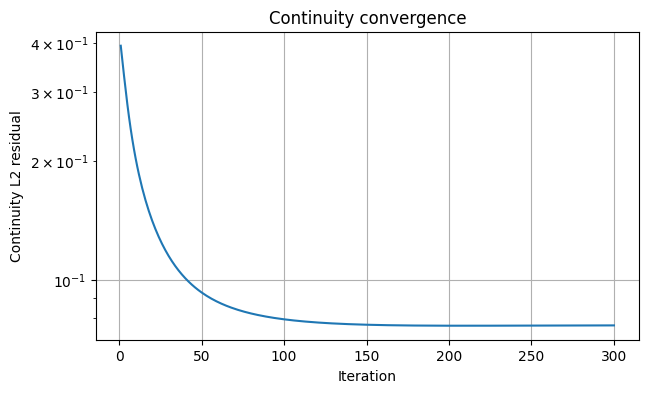

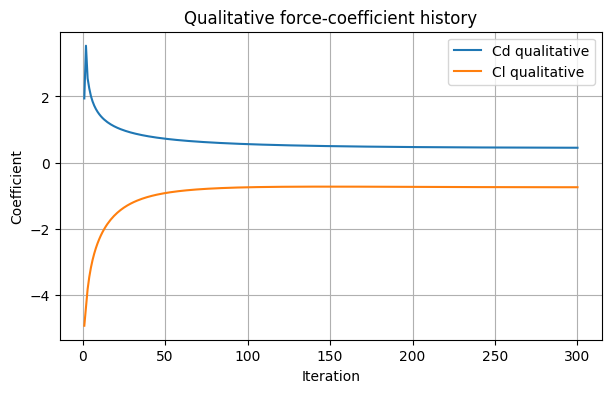

In [ ]:
#@title 5. Plot the primary numerical results
history = read_csv(OUT / "history.csv")
plt.figure(figsize=(7, 4))
plt.semilogy(history["iteration"], history["continuity_l2"])
plt.xlabel("Iteration")
plt.ylabel("Continuity L2 residual")
plt.title("Continuity convergence")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history["iteration"], history["Cd_penalty_qualitative"], label="Cd qualitative")
plt.plot(history["iteration"], history["Cl_penalty_qualitative"], label="Cl qualitative")
plt.xlabel("Iteration")
plt.ylabel("Coefficient")
plt.title("Qualitative force-coefficient history")
plt.legend()
plt.grid(True)
plt.show()

## Inline field visualization

This preview removes the need for ParaView during the basic laboratory workflow. The VTK file is still included in the downloaded results for optional advanced post-processing.

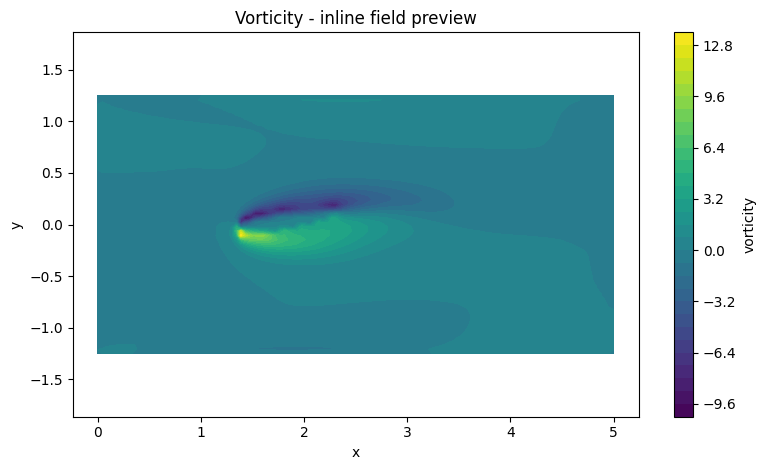

### Generated files
| File | Size |
|---|---:|
| `airfoil_final.vtk` | 1.1 MB |
| `airfoil_mask.vtk` | 418.5 KB |
| `airfoil_summary.txt` | 237 B |
| `airfoil_wall.vtk` | 34.7 KB |
| `history.csv` | 29.8 KB |
| `solver_stderr.log` | 0 B |
| `solver_stdout.log` | 769 B |

In [ ]:
#@title 6. Display the final field and generated files
plot_vtk_scalar(OUT / 'airfoil_final.vtk', 'vorticity')
files = list_outputs(OUT)


## Download results

In [ ]:
#@title 7. Package and download the results
DOWNLOAD_RESULTS = False #@param {type:"boolean"}
RESULTS_ZIP = make_results_zip(OUT, 1)
if DOWNLOAD_RESULTS:
    if IN_COLAB:
        colab_files.download(str(RESULTS_ZIP))
    else:
        print("Local test mode. Archive retained at:", RESULTS_ZIP)
else:
    print("Set DOWNLOAD_RESULTS to True and run this cell when ready to download.")


Results archive: /content/cfd_lab_exp01/experiment_01_results.zip (340.8 KB)
Set DOWNLOAD_RESULTS to True and run this cell when ready to download.


## 7. Compulsory assignment

Run $\alpha=-5^\circ,0^\circ,5^\circ,10^\circ$ at $Re=100$. Compare the wake, pressure-side/suction-side behaviour, final continuity residual, and qualitative lift/drag trends.

## Report checklist

- State the governing equations and boundary conditions.
- Report the complete parameter set and grid.
- Include residual or error history.
- Include the required quantitative comparison.
- Include at least one correctly labelled inline field figure; VTK/ParaView figures are optional unless specifically assigned.
- Distinguish observed numerical behaviour from physical interpretation.
- State the limitations of the supplied teaching model.